# Value-directed free recall — main analysis

Subjects study 15-word lists in which each word carries a point value (1–50), then free-recall
the list and give **one** estimate of the list's average value. The question this notebook
answers: **is that estimate built from the items they recalled, the items they didn't, or both?**

This notebook only orchestrates. Every number is computed by `src/vcbeh`, the same code the
CLI and the test suite use, so nothing here can drift from what is tested.
See [`METHODS.md`](../METHODS.md) for how each measure is defined.

In [1]:
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from vcbeh import ana_vavi, describe_data, load_data, load_res
from vcbeh.plots import publication_style
from vcbeh.plots import res_forpres

DATA_DIR = Path.cwd().parent
DATA_FILE = DATA_DIR / "data_050526_45sess.mat"
GOLDEN_FILE = DATA_DIR / "res_050526_45sess.mat"

## 1. The dataset

In [2]:
trials = load_data(DATA_FILE)
print(describe_data(trials))

trials       : 1080
list_length  : 15
subjects     : 22
sessions     : [1, 2, 3, 4, 5]
list types   : [1, 2]
recall cols  : 60


## 2. Run the analysis

One call produces every measure, three times over: all lists, random-value lists
(`pres_types == 1`), and autocorrelated-value lists (`pres_types == 2`).

In [3]:
res = ana_vavi(trials)

pd.DataFrame(
    [{"field": name, "shape": str(arr.shape)} for name, arr in res.both.to_dict().items()]
).set_index("field").T

field,spcs,pfrs,prec_byval,crps,temp_clusts,est_list,act_rec_list,act_nonrec_list,act_weightrec_list,act_wtascrec_list,...,baseerr_rec_list,abserr_pres_sub,abserr_rec_sub,abserr_wtrec_sub,mm_abserr_pres_sub,mm_signerr_pres_sub,act_rec_sub,act_pres_sub,abserr_rec_sess,abserr_pres_sess
shape,"(22, 15)","(22, 15)","(22, 50)","(22, 29)","(22, 1)","(22, 50)","(22, 50)","(22, 50)","(22, 50)","(22, 50)",...,"(22, 50)","(22, 1)","(22, 1)","(22, 1)","(22, 2)","(22, 2)","(22, 1)","(22, 1)","(22, 5)","(22, 5)"


## 3. Parity check

Before reading any result, confirm this port reproduces the MATLAB pipeline.

Two caveats the check encodes, both established rather than assumed:

- **`signerr_pres_sub`** is in the saved file but is no longer computed by `ana_vavi.m`.
- **The weighted measures in `rand`/`temp` are stale.** They were saved by an earlier
  `ana_vavi` that built output-position weights with `max_op` read from the *unsubset*
  recalls matrix, misaligning every row. `tests/test_ana_vavi_parity.py` reproduces that
  defect and recovers the saved numbers bit-for-bit, which is what identifies them as a
  stale golden file rather than an error here.

In [4]:
STALE_WEIGHTED_FIELDS = {
    "act_weightrec_list", "act_wtascrec_list", "abserr_wtrec_list", "abserr_wtrec_sub",
}

golden = load_res(GOLDEN_FILE)
rows = []
for condition, computed in res.conditions().items():
    got = computed.to_dict()
    for field, expected in golden[condition].items():
        if field not in got:
            rows.append({"condition": condition, "field": field,
                         "status": "not computed by current ana_vavi.m", "max_diff": None})
            continue
        if condition != "both" and field in STALE_WEIGHTED_FIELDS:
            rows.append({"condition": condition, "field": field,
                         "status": "stale golden (legacy weighting bug)", "max_diff": None})
            continue
        actual = got[field]
        same_nan = np.array_equal(np.isnan(actual), np.isnan(expected))
        same_inf = np.array_equal(np.isinf(actual), np.isinf(expected))
        finite = np.isfinite(actual)
        diff = float(np.max(np.abs(actual[finite] - expected[finite]))) if finite.any() else 0.0
        ok = same_nan and same_inf and diff < 1e-11
        rows.append({"condition": condition, "field": field,
                     "status": "MATCH" if ok else "*** MISMATCH ***", "max_diff": diff})

parity = pd.DataFrame(rows)
assert not (parity["status"] == "*** MISMATCH ***").any(), parity[parity.status.str.contains("MISMATCH")]
print(f"{(parity.status == 'MATCH').sum()} fields match; "
      f"worst difference {parity['max_diff'].max():.2e}")
parity.pivot_table(index="field", columns="condition", values="status", aggfunc="first").fillna("-")

52 fields match; worst difference 2.13e-14


condition,both,rand,temp
field,,,
abserr_pres_list,MATCH,MATCH,MATCH
abserr_pres_sess,MATCH,MATCH,MATCH
abserr_pres_sub,MATCH,MATCH,MATCH
abserr_rec_list,MATCH,MATCH,MATCH
abserr_rec_sess,MATCH,MATCH,MATCH
abserr_rec_sub,MATCH,MATCH,MATCH
abserr_wtrec_list,MATCH,stale golden (legacy weighting bug),stale golden (legacy weighting bug)
abserr_wtrec_sub,MATCH,stale golden (legacy weighting bug),stale golden (legacy weighting bug)
act_pres_list,MATCH,MATCH,MATCH


## 4. Recall performance

Random vs autocorrelated lists. Error bars are Loftus–Masson within-subject 95% intervals,
so they support comparison *between* the two curves.

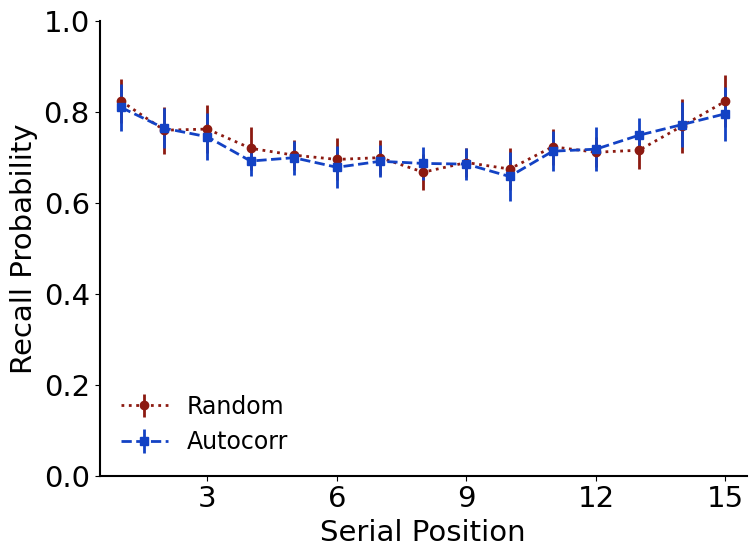

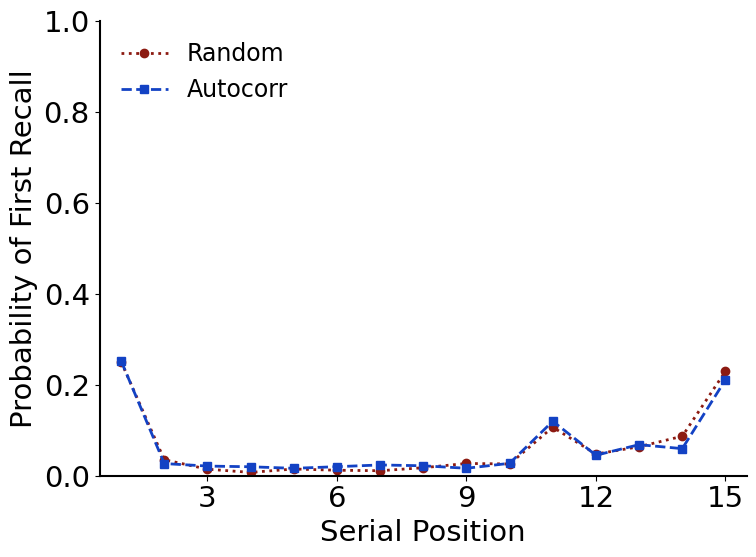

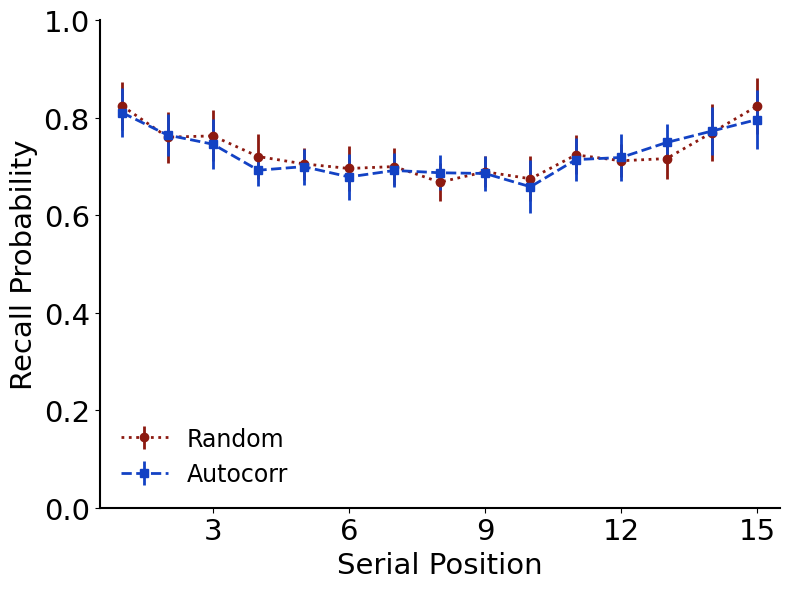

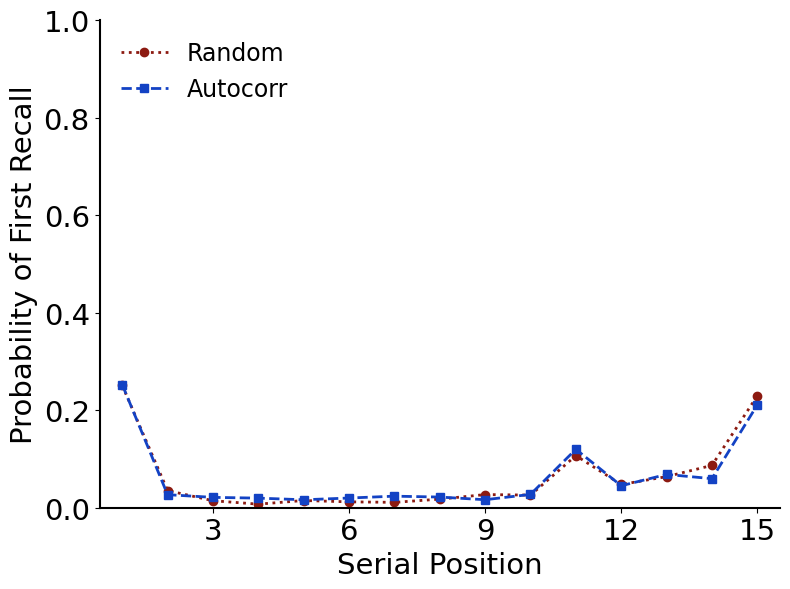

In [5]:
with publication_style():
    display(res_forpres.plot_spc(res))
    display(res_forpres.plot_pfr(res))

The lag-CRP shows the standard contiguity effect: recall jumps to nearby serial positions, and
forward transitions beat backward ones. Lag 0 is undefined and is left out of the line entirely.

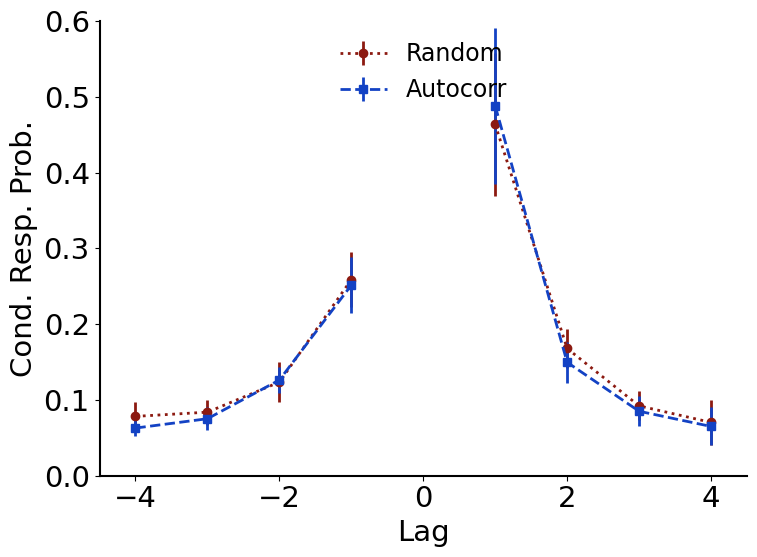

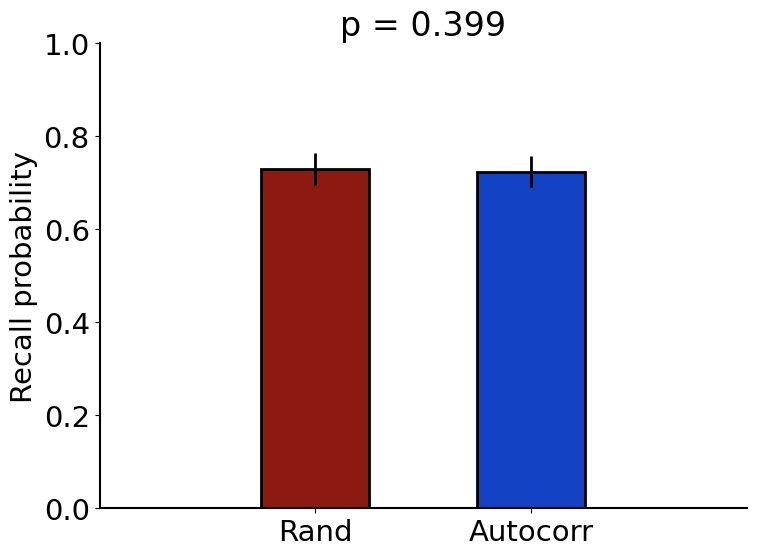

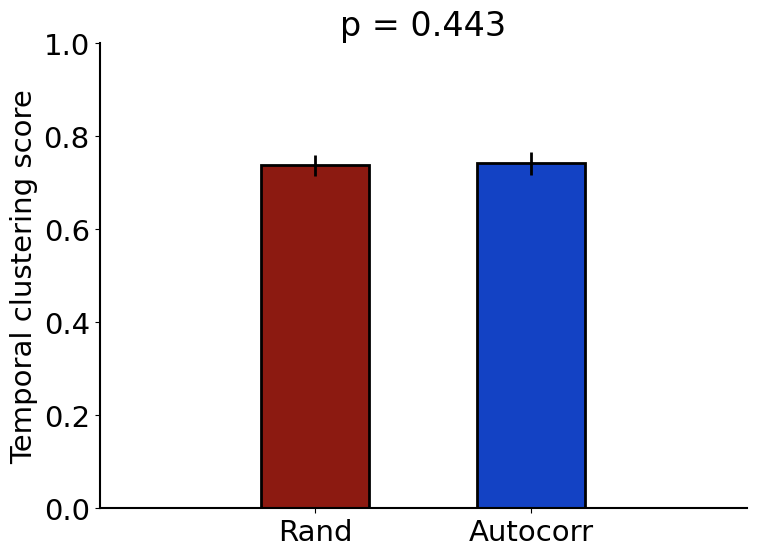

In [6]:
with publication_style():
    display(res_forpres.plot_lag_crp(res, max_abs_lag=4))
    display(res_forpres.plot_recall_probability_bars(res))
    display(res_forpres.plot_temporal_clustering(res))

The list-type comparisons below use a **Wilcoxon signed-rank test** rather than the paired
*t*-test the MATLAB original used. On the raw 26-subject data the paired differences are
decisively non-normal (Shapiro–Wilk p = 0.0018, 0.0005, 0.0003; skew up to +2.0), so the
*t*-test's assumption does not hold there. It does hold on this 22-subject `.mat`
(Shapiro p = 0.75–0.93), which is why the original choice was reasonable at the time.

Both tests are printed, along with the normality check, so the choice is auditable. The bar
charts above carry the Wilcoxon p in their titles.

In [7]:
from vcbeh.stats import format_report
print(format_report(res))

== Random vs autocorrelated lists (Wilcoxon signed-rank) ==
  |value estimation error|   median diff=-0.1250  W=  116.0  p=0.7332  n=22
                             (paired t: mean diff=-0.0226, t(21)=-0.163, p=0.8723; Shapiro p=0.9342)
  recall probability         median diff=+0.0093  W=  100.5  p=0.3986  n=22
                             (paired t: mean diff=+0.0054, t(21)=+0.779, p=0.4447; Shapiro p=0.7929)
  temporal clustering        median diff=-0.0064  W=  102.0  p=0.4434  n=22
                             (paired t: mean diff=-0.0044, t(21)=-0.765, p=0.4529; Shapiro p=0.7454)

== Descriptives, all lists ==
  |value estimation error|   M=  2.875  SD= 1.644  n=22
  recall probability         M=  0.727  SD= 0.159  n=22
  temporal clustering        M=  0.740  SD= 0.110  n=22
  signed value error         M=  0.124  SD= 1.295  n=22

== |value error| vs recall probability ==
  r=-0.5742  p=0.0052  n=22  (fit: y = -0.0557x +0.8869)


## 5. Value estimation

Now the fields that motivated the port. `act_nonrec_list`, `act_nrec_list`, `act_wtdscrec_list`
and `prec_byval` are **absent from every saved `res` file** — they were added to `ana_vavi.m`
after the last one was written, which is why the regressions below could not be run at all
before this.

In [8]:
ll = trials.list_length
c = res.both
nrec = c.act_nrec_list
partial = np.isfinite(nrec) & (nrec > 0) & (nrec < ll)

summary = pd.DataFrame({
    "recalled items": c.act_rec_list[partial],
    "non-recalled items": c.act_nonrec_list[partial],
    "all studied items": c.act_pres_list[partial],
    "subject's estimate": c.est_list[partial],
}).describe().round(2)
summary

,recalled items,non-recalled items,all studied items,subject's estimate
count,898.00,898.00,898.00,898.00
mean,25.17,25.39,25.26,25.47
std,9.96,11.16,9.80,10.11
min,4.17,1.00,8.00,5.00
25%,17.00,16.00,16.93,17.00
50%,25.27,26.00,25.07,25.00
75%,33.63,34.00,33.98,33.00
max,50.00,50.00,42.00,50.00


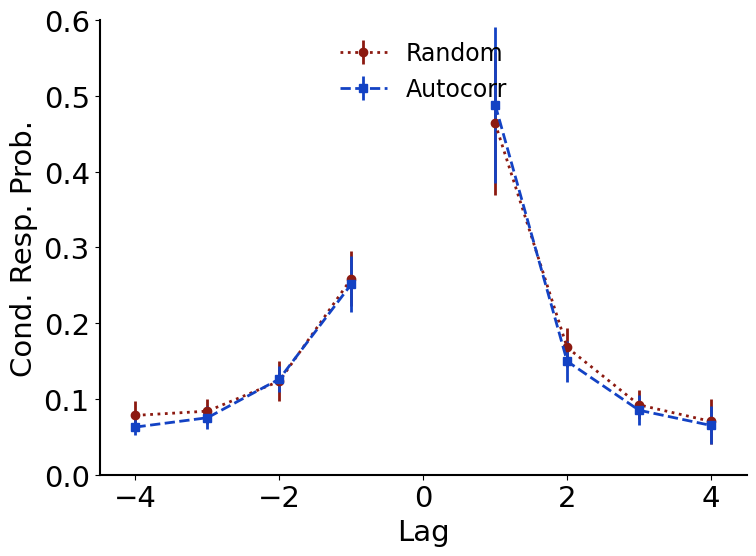

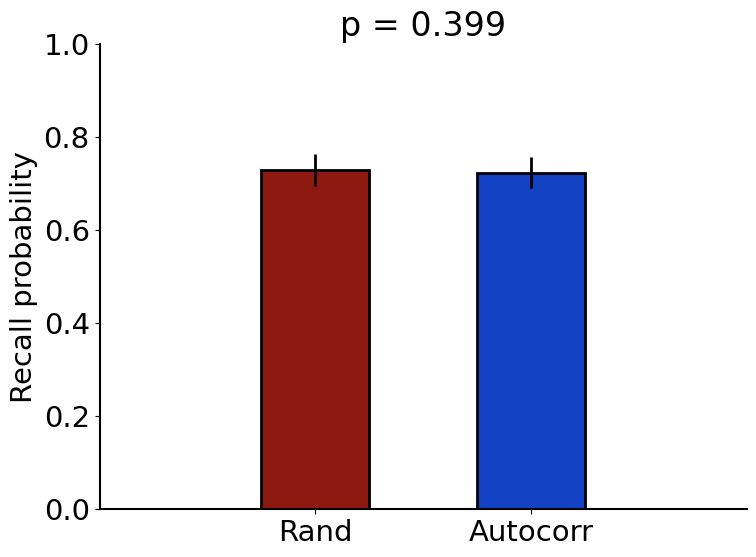

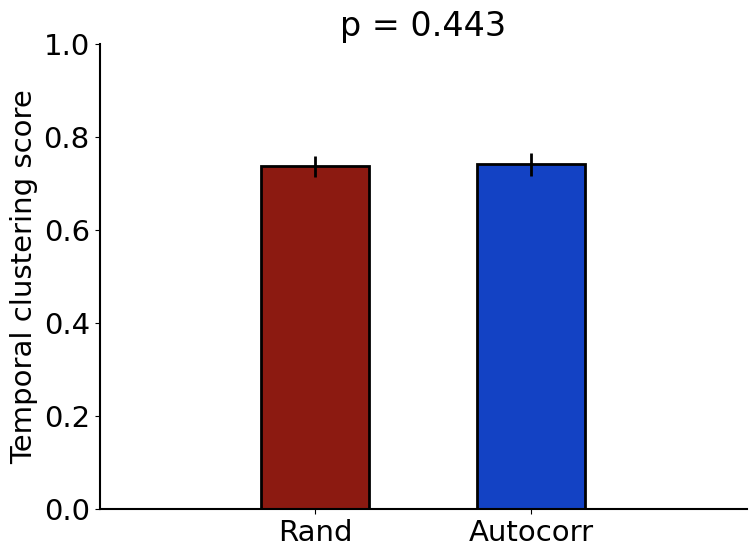

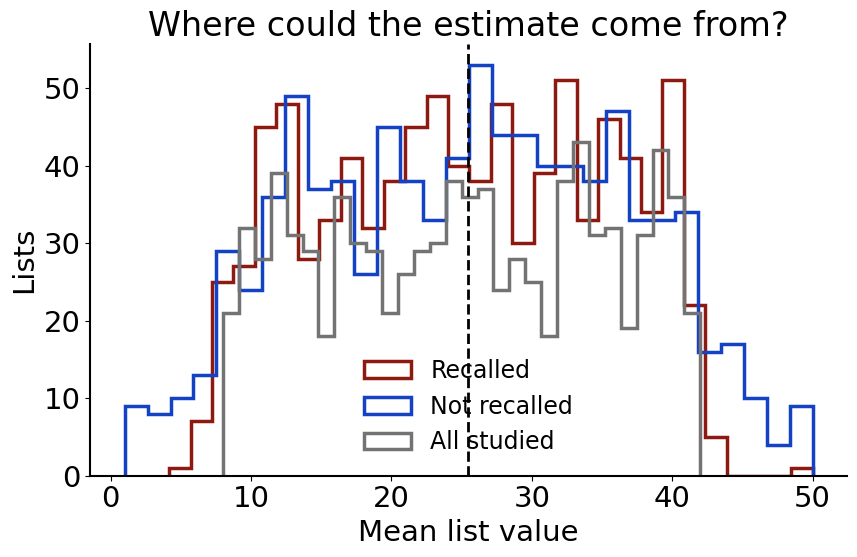

In [9]:
import matplotlib.pyplot as plt

with publication_style():
    fig, ax = plt.subplots(figsize=(9, 6))
    for label, values, color in [
        ("Recalled", c.act_rec_list[partial], "#8c1a11"),
        ("Not recalled", c.act_nonrec_list[partial], "#1342c4"),
        ("All studied", c.act_pres_list[partial], "0.45"),
    ]:
        ax.hist(values, bins=30, histtype="step", linewidth=2.5, label=label, color=color)
    ax.axvline(c.est_list[partial].mean(), color="k", linestyle="--", linewidth=2)
    ax.set(xlabel="Mean list value", ylabel="Lists",
           title="Where could the estimate come from?")
    ax.legend(frameon=False)
    plt.show()

Estimation error, aggregated three ways. Session ordinals, not session numbers — see `METHODS.md`.

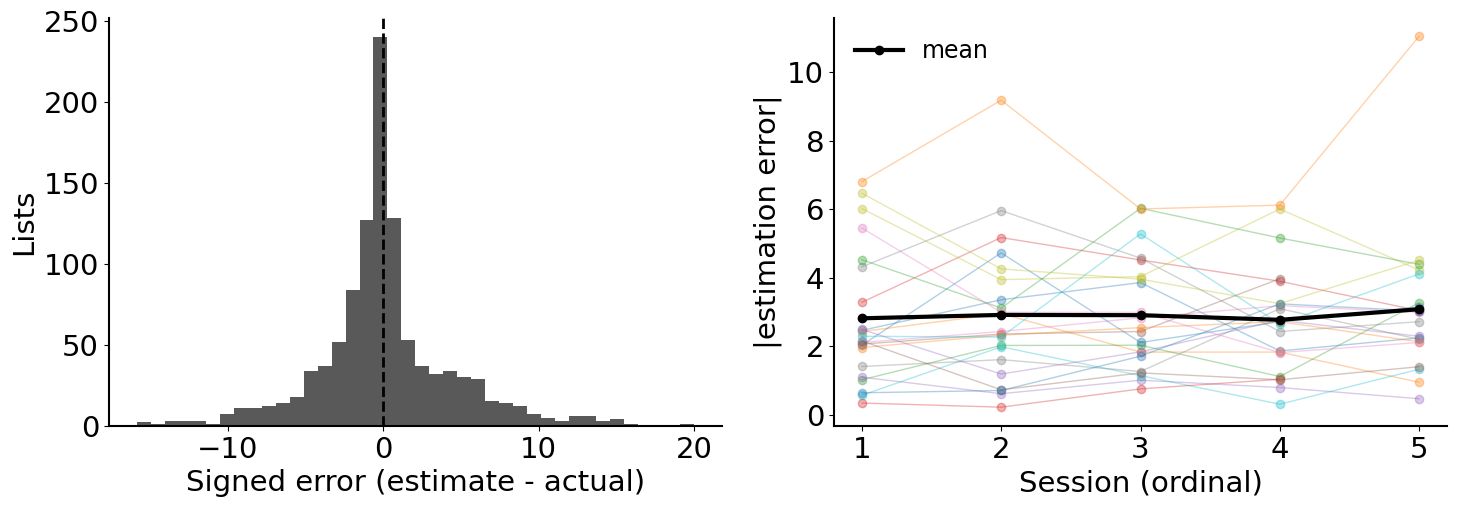

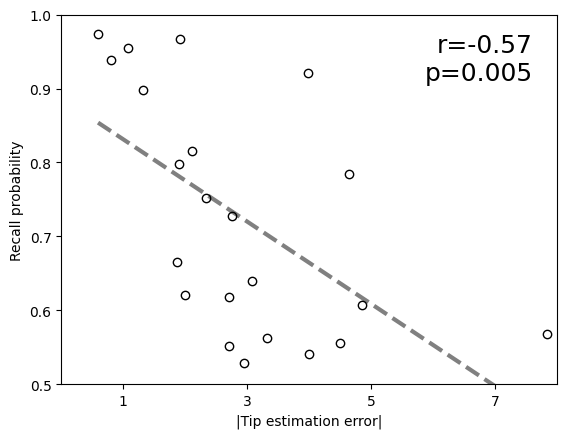

In [10]:
with publication_style():
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    axes[0].hist(c.signerr_pres_list[np.isfinite(c.signerr_pres_list)], bins=40, color="0.35")
    axes[0].axvline(0, color="k", linestyle="--", linewidth=2)
    axes[0].set(xlabel="Signed error (estimate - actual)", ylabel="Lists")

    sess = c.abserr_pres_sess
    axes[1].plot(np.arange(1, sess.shape[1] + 1), sess.T, "o-", alpha=0.35, linewidth=1)
    axes[1].plot(np.arange(1, sess.shape[1] + 1), np.nanmean(sess, axis=0),
                 "k-o", linewidth=3, label="mean")
    axes[1].set(xlabel="Session (ordinal)", ylabel="|estimation error|")
    axes[1].legend(frameon=False)
    plt.show()

display(res_forpres.plot_error_vs_recall(res))

## 6. Regressions

One mixed-effects model per recall count, since the natural weighting
(`nrec/ll` and `(ll-nrec)/ll`) differs list by list. Random intercept per subject.
Lists with `nrec == ll` are excluded because both accounts coincide there.

`statsmodels` is forced to match `fitlme`: maximum likelihood rather than REML, *t*-tests on
residual degrees of freedom rather than z-tests, and a **conditional** R² that includes the
random effects. Each model is fit with several optimizers and the highest-likelihood fit is
kept — L-BFGS alone will sometimes report convergence at a degenerate boundary solution.

In [11]:
from vcbeh.stats import recalled_unweighted, recalled_vs_nonrecalled

additive = recalled_vs_nonrecalled(res, ll)
additive.round(4)

,nrec,n_lists,n_subjects,R2,b_int,p_int,b_ValueRecall,p_ValueRecall,b_ValueNotRecall,p_ValueNotRecall
0,7,76,17,0.8184,2.0223,0.2511,1.3790,0.0,0.6336,0.0011
1,8,87,16,0.7482,2.1456,0.1781,1.0629,0.0,0.6809,0.0033
2,9,108,19,0.7458,2.2519,0.1316,0.7816,0.0,1.1292,0.0000
3,10,114,18,0.7796,3.8140,0.0025,0.8889,0.0,0.8277,0.0007
4,11,93,20,0.8354,2.3793,0.1095,0.8439,0.0,1.1754,0.0003
5,12,103,20,0.8981,1.6531,0.1683,0.7935,0.0,1.4856,0.0000
6,13,97,19,0.9056,1.5025,0.1442,0.9406,0.0,0.9820,0.0117


Both terms are positive and significant at every recall count: the estimate tracks the value of
the items that were **not** recalled as well as the value of those that were. A pure
recalled-items account would put the non-recalled coefficient at zero.

In [12]:
interaction = recalled_unweighted(res, ll)
interaction.round(4)

,nrec,n_lists,n_subjects,R2,b_int,p_int,b_ValueRecall,p_ValueRecall,b_ValueNotRecall,p_ValueNotRecall,b_ValueRecall:ValueNotRecall,p_ValueRecall:ValueNotRecall
0,9,108,19,0.7458,2.5087,0.5176,0.4587,0.0099,1.0992,0.0259,0.0011,0.9424
1,10,114,18,0.7798,3.9179,0.2089,0.5881,0.0002,0.8116,0.1080,0.0006,0.9709
2,11,93,20,0.8333,3.4008,0.3177,0.5756,0.0004,0.9785,0.1447,0.0071,0.7385
3,12,103,20,0.8997,4.9218,0.0457,0.4894,0.0000,0.7455,0.1778,0.0286,0.1299
4,13,97,19,0.9052,-0.5647,0.7971,0.9172,0.0000,1.6649,0.0286,-0.0282,0.2891
5,14,116,15,0.9384,0.0063,0.9959,0.9301,0.0000,2.2563,0.0076,-0.0412,0.1857


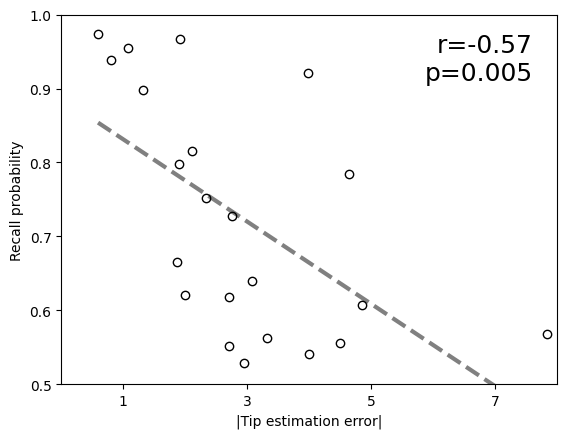

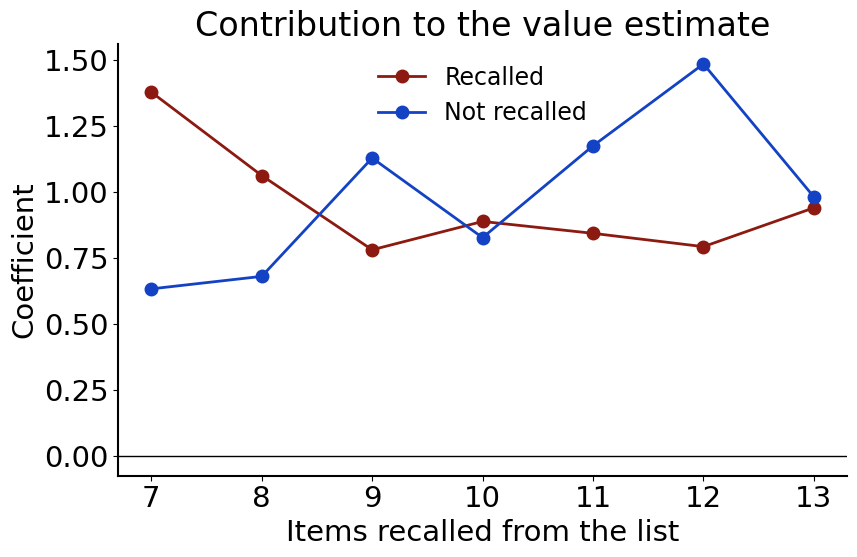

In [13]:
with publication_style():
    fig, ax = plt.subplots(figsize=(9, 6))
    for col, label, color in [("b_ValueRecall", "Recalled", "#8c1a11"),
                              ("b_ValueNotRecall", "Not recalled", "#1342c4")]:
        ax.plot(additive["nrec"], additive[col], "o-", label=label, color=color, markersize=9)
    ax.axhline(0, color="k", linewidth=1)
    ax.set(xlabel="Items recalled from the list", ylabel="Coefficient",
           title="Contribution to the value estimate")
    ax.legend(frameon=False)
    plt.show()

## Notes on two defects reproduced deliberately

**`act_wtascrec_list` is not ascending.** `ana_vavi.m:138` builds the "ascending"
output-position weight from the descending weight written on the line above, so it comes out as
a symmetric tent, `op*(max_op-op+1)`. Every saved result was computed this way, so the port
keeps it by default; `ana_vavi(trials, ascending_weight_bug=False)` gives the intended weight
and changes that field by up to ~8 value units. Nothing in this notebook depends on it.

**`bysess=True` behaves differently here than in MATLAB.** There, `data.session` is `uint8`,
so `1000*session` saturates at 255 and every session received the same offset — the split
silently never happened. This port casts to `int64` at load time, so it does what it says.
There is no saved result to validate it against.

In [14]:
alt = ana_vavi(trials, ascending_weight_bug=False)
delta = np.abs(alt.both.act_wtascrec_list - res.both.act_wtascrec_list)
print(f"act_wtascrec_list changes by up to {np.nanmax(delta):.2f} value units")
print(f"every other field is identical: "
      f"{np.array_equal(alt.both.act_rec_list, res.both.act_rec_list, equal_nan=True)}")

act_wtascrec_list changes by up to 7.97 value units
every other field is identical: True


### 6b. The original `ValueAll x ValueRecalled` model

An earlier write-up of this analysis reported a different model from the sweeps above:

```
SubjectEstValue ~ 1 + ValueAll * ValueRecalled + (1|Subject)
```

with one observation per list per participant, and these coefficients:

| | Estimate | p |
|---|---|---|
| Value from All | 0.902 | <10⁻¹⁰ |
| Value from Recalled | 0.155 | 0.036 |
| Interaction | −0.003 | 0.082 |
| Intercept | 0.559 | 0.531 |
| R² | 0.84 | — |

**That model is not in the MATLAB on disk.** `linreg_estval_pressrecallv2.m` preallocates a
`ValuePres` variable at line 14 and never assigns it, while its LaTeX table block at line 92
labels the coefficients `'Tip, Studied Items'` / `'Tip, Recalled Items'` with `inds = [1;3;2;4]` —
so coefficient 3 was the *studied* term. That only works if the formula was
`ValueRecall*ValuePres`. The script was later edited to use `ValueNotRecall`, orphaning
`ValuePres` and leaving the table labels describing a model it no longer fits.

Two things to note about how this model differs from section 7's:

- **`ValueRecalled` is the raw mean value of the recalled items**, not the list-share-weighted
  `ValueRecallW`. They are on different scales and are not interchangeable.
- **The two predictors are collinear rather than complementary.** `ValueAll` already contains the
  recalled items, so the recalled term measures what it adds *beyond* the list as a whole — unlike
  the recalled/non-recalled split, whose two terms sum to `ValueAll`.

In [15]:
from vcbeh.stats import all_vs_recalled, format_all_vs_recalled

published = pd.DataFrame({
    "term": ["Intercept", "ValueAll", "ValueRecalled", "ValueAll:ValueRecalled"],
    "published estimate": [0.559, 0.902, 0.155, -0.003],
    "published p": [0.531, np.nan, 0.036, 0.082],
})

# The published model was fit with uncentred predictors, so reproduce it that way.
reproduced = all_vs_recalled(res, center=False)

check = (published.merge(reproduced[["term", "label", "estimate", "p"]], on="term")
         .rename(columns={"label": "coefficient", "estimate": "reproduced estimate",
                          "p": "reproduced p"}))
check[["coefficient", "published estimate", "reproduced estimate",
       "published p", "reproduced p"]].round(4)

,coefficient,published estimate,reproduced estimate,published p,reproduced p
0,Intercept,0.559,0.5593,0.531,0.5306
1,Value from ALL studied items,0.902,0.9019,NaN,0.0000
2,Value from RECALLED items,0.155,0.1555,0.036,0.0360
3,Interaction (All x Recalled),-0.003,-0.0026,0.082,0.0820


In [16]:
print(f"R2 conditional = {reproduced['R2'].iloc[0]:.4f}   "
      f"marginal = {reproduced['R2_marginal'].iloc[0]:.4f}   (published: 0.84)")
print(f"n = {int(reproduced['n_lists'].iloc[0])} lists, "
      f"{int(reproduced['n_subjects'].iloc[0])} subjects")

R2 conditional = 0.8311   marginal = 0.8366   (published: 0.84)
n = 1080 lists, 22 subjects


#### The recalled-value term depends on where zero sits

`ValueAll` and `ValueRecalled` **interact** in this model. That makes the coefficient on
`ValueRecalled` its effect *where `ValueAll` is zero* — a list whose average value is nothing.
Observed list averages run from about 8 to 42, so that is an extrapolation well outside the data.

Re-centring both predictors at their means moves the reference to a typical list. It is the same
fit — identical R², identical interaction — seen from a sensible reference point:

In [17]:
comparison = []
for centred in (False, True):
    fit = all_vs_recalled(res, center=centred).set_index("term")
    comparison.append({
        "predictors": "centred" if centred else "uncentred (as published)",
        "Value from ALL": f"{fit.loc['ValueAll', 'estimate']:.3f} (p={fit.loc['ValueAll', 'p']:.3g})",
        "Value from RECALLED": f"{fit.loc['ValueRecalled', 'estimate']:.3f} "
                               f"(p={fit.loc['ValueRecalled', 'p']:.3f})",
        "Interaction": f"{fit.loc['ValueAll:ValueRecalled', 'estimate']:+.4f} "
                       f"(p={fit.loc['ValueAll:ValueRecalled', 'p']:.3f})",
        "R2": f"{fit['R2'].iloc[0]:.3f}",
    })
pd.DataFrame(comparison).set_index("predictors")

,Value from ALL,Value from RECALLED,Interaction,R2
predictors,,,,
uncentred (as published),0.902 (p=7.61e-31),0.155 (p=0.036),-0.0026 (p=0.082),0.831
centred,0.838 (p=9.06e-35),0.091 (p=0.161),-0.0026 (p=0.082),0.831


**The reported contribution from recalled items does not survive centring**: 0.155 (p=0.036)
becomes 0.091 (p=0.161). The R² and the interaction term are untouched, which is the tell — this
is one fit described from two reference points, not two different models.

The uncentred number is not *wrong*; it just answers a question about lists with zero average
value. Read as "how much recalled value contributes for a typical list", the centred version is
the one to quote, and on this data that contribution is not distinguishable from zero once the
whole list's value is already in the model.

Every model elsewhere in this notebook is fit **uncentred**, matching how these analyses were
originally run. Pass `center=True` to any of them for the centred view.

Every coefficient and p-value reproduces. The one apparent gap — R² 0.84 vs 0.831 — is a
difference of definition, not a discrepancy: **0.84 is the marginal R²** (fixed effects only,
0.8366). The conditional version, which includes the subject random intercepts and is what MATLAB's
`Rsquared.Ordinary` reports, is 0.831. Both are printed above.

### The same model on the current data

Sections 7–8 use the raw event log (26 subjects, 1120 lists) rather than the 22-subject `.mat`.
Below is the same model there, pooled and then split by list type.

In [18]:
from vcbeh.rawio import load_raw

raw_for_6b = load_raw(DATA_DIR.parent.parent / "data", include_session0=False)
res_6b = ana_vavi(raw_for_6b)

print(format_all_vs_recalled(all_vs_recalled(res_6b), "Pooled (26 subjects)"))
print()
print(format_all_vs_recalled(all_vs_recalled(res_6b, by_condition=True), "Split by list type"))

== Pooled (26 subjects) ==
  predictors uncentred: intercept is at a predictor value of 0
  All lists n=1119 lists, 26 subjects, R2=0.818 conditional / 0.825 marginal
      Intercept                        +0.4128  t= +0.453  p=0.6507
      Value from ALL studied items     +0.9293  t=+12.321  p=8.556e-33
      Value from RECALLED items        +0.1439  t= +1.968  p=0.04928
      Interaction (All x Recalled)     -0.0032  t= -2.144  p=0.03225



== Split by list type ==
  predictors uncentred: intercept is at a predictor value of 0
  Random    n=557 lists, 26 subjects, R2=0.809 conditional / 0.804 marginal
      Intercept                        +0.0491  t= +0.039  p=0.9692
      Value from ALL studied items     +0.9276  t= +8.714  p=3.4e-17
      Value from RECALLED items        +0.2009  t= +1.923  p=0.05505
      Interaction (All x Recalled)     -0.0048  t= -2.248  p=0.025
  Autocorr  n=562 lists, 26 subjects, R2=0.840 conditional / 0.849 marginal
      Intercept                        +1.2396  t= +0.993  p=0.3213
      Value from ALL studied items     +0.9176  t= +8.630  p=6.391e-17
      Value from RECALLED items        +0.0780  t= +0.764  p=0.4451
      Interaction (All x Recalled)     -0.0012  t= -0.602  p=0.5471


The pooled result holds up on the larger dataset: value from ALL studied items ≈ 0.93, a small
positive contribution from recalled value (0.144, p=0.049), and a negligible interaction.

Splitting by list type is the more interesting part. The recalled-value term is the larger and
near-significant one in **random** lists (0.201, p=0.055) and essentially absent in
**autocorrelated** lists (0.078, p=0.45) — the same direction as the non-recalled asymmetry in
section 8, and, like it, not something this sample size can establish.

One caution: with `ValueAll` and `ValueRecalled` being collinear by construction, the split of
explanatory weight between them is less stable than the recalled/non-recalled decomposition, where
the two predictors sum exactly to the list value.

---

## 7. Bias by list type

Everything above pools random and autocorrelated lists together, so a difference between them
would be invisible. This section fits **four mixed models** — one per list type, twice over — to
ask whether the two conditions are estimated differently.

**Round 1, uncorrected:** `ValueEst ~ ValuePres + (1|Subject)`

**Round 2, with the recall/non-recall correction:**
`ValueEst ~ ValueRecallW + ValueNotRecallW + (1|Subject)`, where each list is weighted by **its
own** recall count:

```
ValueRecallW    = (nrec/ll)      * value of the recalled items
ValueNotRecallW = ((ll-nrec)/ll) * value of the non-recalled items
```

Per-list weighting is what makes this one model per condition instead of seven. The sweeps in
section 6 fit one model per recall count because the original MATLAB wanted a like-for-like
comparison at fixed `nrec`; that constraint does not apply here, and splitting *those* by
condition would leave 38–58 lists per cell.

### A different dataset from sections 1–6

This section rebuilds the trials from the **raw VCBehOnly event log** rather than the `.mat`
file, which gives **26 subjects / 1120 lists** instead of 22 / 1080. Sections 1–6 stay on the
`.mat` because the parity check in section 3 is what demonstrates the port is faithful — that has
to keep comparing against the golden file.

The loader is verified: it reproduces `data_050526_45sess.mat` and `data_050526_xs0.mat` exactly,
matrix for matrix (`tests/test_rawio.py`).

Note that excluding session 0 also removes 8 subjects who did nothing else, which is why this is
26 subjects and not the full 34.

In [19]:
from vcbeh.rawio import load_raw
from vcbeh.stats import condition_contrast, condition_models
from vcbeh.stats import format_condition_models, format_contrast
from vcbeh.stats.linreg import CONDITION_LABELS, TERM_LABELS

RAW_DIR = DATA_DIR.parent.parent / "data"

raw = load_raw(RAW_DIR, include_session0=False)
raw_res = ana_vavi(raw)
raw_ll = raw.list_length
print(describe_data(raw))

trials       : 1120
list_length  : 15
subjects     : 26
sessions     : [1, 2, 3, 4, 5]
list types   : [1, 2]
recall cols  : 51


In [20]:
uncorrected = condition_models(raw_res, raw_ll, corrected=False)
corrected = condition_models(raw_res, raw_ll, corrected=True)

print(format_condition_models(uncorrected, "ROUND 1 - estimate ~ actual list value"))
print()
print(format_condition_models(corrected, "ROUND 2 - estimate ~ recalled + non-recalled value"))

== ROUND 1 - estimate ~ actual list value ==
  predictors uncentred: intercept is at a predictor value of 0
  Random    n=558 lists, 26 subjects, R2=0.805
      Intercept                               +2.6052 [+1.5095, +3.7010]  t= +4.670  p=3.777e-06
      Value of ALL studied items              +0.8881 [+0.8498, +0.9264]  t=+45.550  p=8.477e-190
  Autocorr  n=562 lists, 26 subjects, R2=0.839
      Intercept                               +1.8909 [+0.7081, +3.0737]  t= +3.140  p=0.001778
      Value of ALL studied items              +0.9332 [+0.8988, +0.9677]  t=+53.163  p=5.456e-221

== ROUND 2 - estimate ~ recalled + non-recalled value ==
  predictors uncentred: intercept is at a predictor value of 0
  Random    n=470 lists, 26 subjects, R2=0.798
      Intercept                               +3.0023 [+1.7729, +4.2317]  t= +4.799  p=2.152e-06
      Value of RECALLED items                 +0.8946 [+0.8423, +0.9470]  t=+33.579  p=1.297e-126
      Value of NON-RECALLED items             

### Do the conditions actually differ?

Fitting the two separately shows what each looks like but cannot test whether they differ. These
pooled models carry a `ListType` interaction, and those terms are the test.

In [21]:
contrast_uncorrected = condition_contrast(raw_res, raw_ll, corrected=False)
contrast_corrected = condition_contrast(raw_res, raw_ll, corrected=True)

print(format_contrast(contrast_uncorrected, "ROUND 1 contrast"))
print()
print(format_contrast(contrast_corrected, "ROUND 2 contrast"))

== ROUND 1 contrast ==
  predictors uncentred: intercept is at a predictor value of 0
  n=1120 lists, 26 subjects, R2=0.817   (the 'x list type' rows test the difference)
      Intercept                         +2.4707  t= +4.108  p=4.274e-05  *
      List type (Autocorr vs Random)    -0.7259  t= -1.025  p=0.3057
      Value of ALL studied items        +0.8896  t=+46.784  p=2.425e-265  *
      ALL studied  x  list type         +0.0463  t= +1.777  p=0.07589

== ROUND 2 contrast ==
  predictors uncentred: intercept is at a predictor value of 0
  n=937 lists, 26 subjects, R2=0.803   (the 'x list type' rows test the difference)
      Intercept                         +2.8779  t= +4.333  p=1.634e-05  *
      List type (Autocorr vs Random)    -0.9302  t= -1.155  p=0.2485
      Value of RECALLED items           +0.8956  t=+33.711  p=1.817e-163  *
      RECALLED  x  list type            +0.0364  t= +1.023  p=0.3068
      Value of NON-RECALLED items       +0.8340  t=+23.706  p=1.432e-97  *
    

### Figures

The dashed diagonal is perfect accuracy. Both fitted lines cross it — above at low list values,
below at high ones — which is estimates compressing toward the middle of the range.

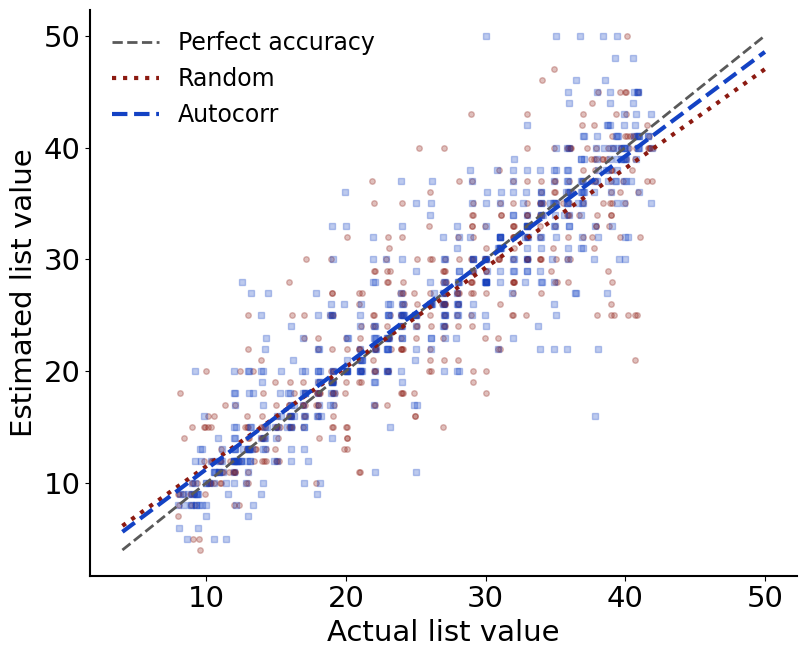

In [22]:
from vcbeh.plots import (
    plot_condition_coefficients, plot_estimate_vs_actual, plot_partial_effects,
)

with publication_style():
    display(plot_estimate_vs_actual(raw_res, raw_ll))

With two predictors, a raw scatter against either one alone would confound them — recalled and
non-recalled value both track the list's overall value. Each panel below holds the other
predictor at its mean.

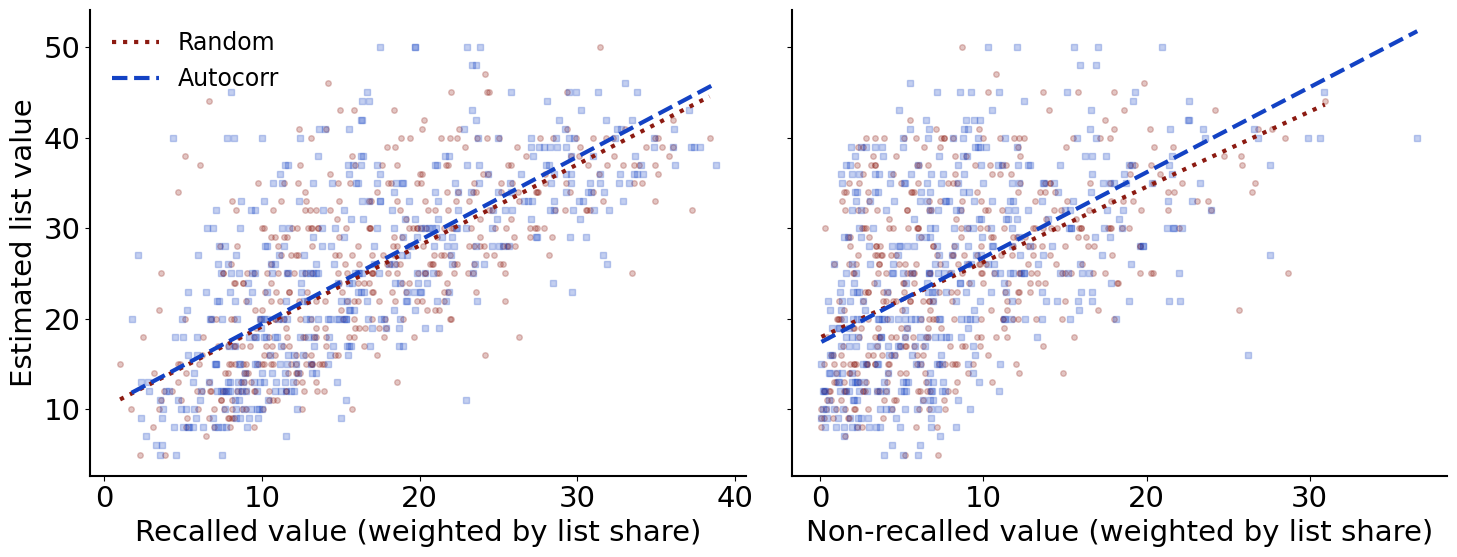

In [23]:
with publication_style():
    display(plot_partial_effects(raw_res, raw_ll))

All four models in one panel. The dashed line at 1.0 is where an estimate would track value
one-for-one. Where the two colours' intervals overlap, the conditions are not distinguishable on
that term.

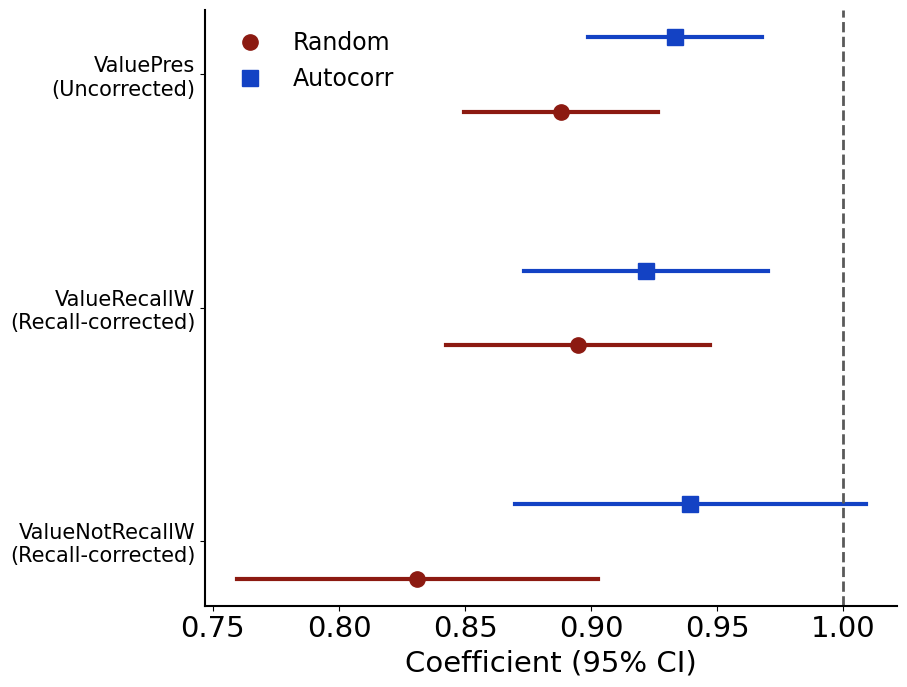

In [24]:
with publication_style():
    display(plot_condition_coefficients(raw_res, raw_ll))

---

## 8. Summary of findings

### The headline comparison

The two rounds answer slightly different questions, and their coefficients are directly
comparable because of how the predictors are built:

```
Value of RECALLED items  +  Value of NON-RECALLED items  ==  Value of ALL studied items
```

Each of the two round-2 predictors is already scaled by the share of the list it covers, so they
sum exactly to the whole-list value. That means **round 1 is round 2 with the two sources forced
to count equally** — if both round-2 coefficients were identical, the model would collapse to
round 1. Round 2 just lets the data say whether recalled and non-recalled items carry the same
weight.

The table below refits round 1 on *exactly* the lists round 2 uses, so the three coefficients are
measured on the same data.

In [25]:
headline = []
r1_matched = condition_models(raw_res, raw_ll, corrected=False, partial_only=True)

for cond in ("rand", "temp"):
    row = {"List type": CONDITION_LABELS[cond]}
    for table, term in ((r1_matched, "ValuePres"),
                        (corrected, "ValueRecallW"),
                        (corrected, "ValueNotRecallW")):
        hit = table[(table["condition"] == cond) & (table["term"] == term)].iloc[0]
        row[TERM_LABELS[term]] = f"{hit['estimate']:.3f}  [{hit['ci_low']:.3f}, {hit['ci_high']:.3f}]"
    row["n lists"] = int(r1_matched[r1_matched["condition"] == cond]["n_lists"].iloc[0])
    headline.append(row)

pd.DataFrame(headline).set_index("List type")

,Value of ALL studied items,Value of RECALLED items,Value of NON-RECALLED items,n lists
List type,,,,
Random,"0.872 [0.830, 0.915]","0.895 [0.842, 0.947]","0.831 [0.759, 0.903]",470
Autocorr,"0.927 [0.887, 0.968]","0.922 [0.873, 0.970]","0.939 [0.870, 1.009]",467


### How to read a coefficient

A value is a number of points from 1 to 50, and so is the estimate, so each coefficient is
**points of estimate per point of actual value**. A coefficient of 0.89 means that when the value
goes up by 1 point, the estimate goes up by only 0.89 — the estimate under-tracks.

Two things that are easy to misread:

- **The printed *p*-values test against zero**, which is not the interesting null. Nobody doubts
  the estimate tracks value; that is why they come out at 1e-190. The question is whether a
  coefficient differs from **1** (perfect tracking), and that is read off the confidence interval.
- **The intercept is not a bias estimate on its own.** It is the predicted estimate at a true
  value of zero, which is far outside the observed range (list averages run roughly 8–45). It only
  means something together with the slope: a positive intercept with a slope below 1 puts the
  fitted line above the identity line at low values and below it at high ones.

In [26]:
full_table = pd.concat([
    uncorrected.assign(model="1. Uncorrected"),
    corrected.assign(model="2. Recall-corrected"),
], ignore_index=True)

full_table[[
    "model", "list_type", "label", "estimate", "se", "ci_low", "ci_high",
    "t", "p", "n_lists", "n_subjects", "R2",
]].rename(columns={"label": "coefficient", "list_type": "list type"}).style.format({
    "estimate": "{:+.4f}", "se": "{:.4f}", "ci_low": "{:+.4f}", "ci_high": "{:+.4f}",
    "t": "{:+.2f}", "p": "{:.3g}", "R2": "{:.3f}",
}).hide(axis="index")

model,list type,coefficient,estimate,se,ci_low,ci_high,t,p,n_lists,n_subjects,R2
1. Uncorrected,Random,Intercept,+2.6052,0.5578,+1.5095,+3.7010,+4.67,3.78e-06,558,26,0.805
1. Uncorrected,Random,Value of ALL studied items,+0.8881,0.0195,+0.8498,+0.9264,+45.55,8.48e-190,558,26,0.805
1. Uncorrected,Autocorr,Intercept,+1.8909,0.6022,+0.7081,+3.0737,+3.14,0.00178,562,26,0.839
1. Uncorrected,Autocorr,Value of ALL studied items,+0.9332,0.0176,+0.8988,+0.9677,+53.16,5.46e-221,562,26,0.839
2. Recall-corrected,Random,Intercept,+3.0023,0.6256,+1.7729,+4.2317,+4.80,2.15e-06,470,26,0.798
2. Recall-corrected,Random,Value of RECALLED items,+0.8946,0.0266,+0.8423,+0.9470,+33.58,1.3e-126,470,26,0.798
2. Recall-corrected,Random,Value of NON-RECALLED items,+0.8311,0.0365,+0.7594,+0.9028,+22.78,8.1e-78,470,26,0.798
2. Recall-corrected,Autocorr,Intercept,+2.0487,0.6682,+0.7356,+3.3618,+3.07,0.0023,467,26,0.824
2. Recall-corrected,Autocorr,Value of RECALLED items,+0.9216,0.0246,+0.8732,+0.9699,+37.45,2.47e-142,467,26,0.824
2. Recall-corrected,Autocorr,Value of NON-RECALLED items,+0.9393,0.0353,+0.8699,+1.0088,+26.57,3.04e-95,467,26,0.824


### Does any of it differ by list type?

The `x list type` rows are the test of whether the *slopes* differ. Everything else describes the
random-list baseline.

One caution on the `List type (Autocorr vs Random)` row: predictors here are **uncentred**, so
that coefficient is the gap between conditions at a list value of *zero*, which is outside the
observed range of roughly 8 to 42. Centred — the gap for a typical list — the same coefficient is
+0.451 (p=0.075) rather than −0.726 (p=0.31); pass `center=True` to see that version. The
interaction rows are slope differences and are unaffected by centring either way.

In [27]:
contrasts = pd.concat([
    contrast_uncorrected.assign(model="1. Uncorrected"),
    contrast_corrected.assign(model="2. Recall-corrected"),
], ignore_index=True)

interactions = contrasts[contrasts["term"].str.contains("ListType")]
interactions[["model", "label", "estimate", "t", "p"]].rename(
    columns={"label": "coefficient"}
).round(4).style.hide(axis="index")

model,coefficient,estimate,t,p
1. Uncorrected,List type (Autocorr vs Random),-0.725900,-1.024800,0.305700
1. Uncorrected,ALL studied x list type,0.046300,1.776700,0.075900
2. Recall-corrected,List type (Autocorr vs Random),-0.930200,-1.154700,0.248500
2. Recall-corrected,RECALLED x list type,0.036400,1.022600,0.306800
2. Recall-corrected,NON-RECALLED x list type,0.088200,1.926300,0.054400


### What the four models show

**1. Estimates under-track value, in both conditions.** On matched lists the coefficient on the
value of ALL studied items is **0.872** [0.830, 0.915] for random lists and **0.927**
[0.887, 0.968] for autocorrelated ones. Neither interval contains 1. Together with positive
intercepts, that means low-value lists are overestimated and high-value lists underestimated —
the fitted lines cross the identity line near the middle of the range, which is what the
`estimate_vs_actual` figure shows.

**2. Non-recalled items contribute nearly as much as recalled ones.**

| | Value of RECALLED items | Value of NON-RECALLED items |
|---|---|---|
| Random | 0.895 [0.842, 0.947] | **0.831** [0.759, 0.903] |
| Autocorrelated | 0.922 [0.873, 0.970] | **0.939** [0.870, 1.009] |

If the estimate were built only from what was recalled, the non-recalled coefficient would be
zero. It is nowhere near it. In random lists the recalled items do carry more weight
(0.895 vs 0.831); in autocorrelated lists the two are effectively equal, with the non-recalled
term marginally larger.

In both conditions the ALL-studied coefficient lands between the two — as it must, being the
compromise round 1 is forced into.

**3. No significant difference between conditions, but a consistent trend.** None of the
interaction terms clears 0.05:

| Model | Interaction | *p* |
|---|---|---|
| Uncorrected | ALL studied x list type | 0.076 |
| Recall-corrected | RECALLED x list type | 0.307 |
| Recall-corrected | NON-RECALLED x list type | **0.054** |

Every autocorrelated coefficient sits closer to 1 than its random counterpart, and the gap is
widest on the non-recalled term — where the random interval excludes 1 (0.759–0.903) while the
autocorrelated one contains it (0.870–1.009). The direction is consistent across all three terms,
but at 26 subjects it does not separate from chance. **A lead, not a result.**

### Caveats

- These models use the raw data (26 subjects, 1120 lists); sections 1–6 use the 22-subject `.mat`.
- Round 2 must drop lists where nothing or everything was recalled (937 of 1120 survive), since
  the decomposition is undefined there. The headline table above refits round 1 on those same
  lists; the full table further up reports round 1 on all 1120.
- Nothing here uses `act_wtascrec_list`, so the B1 defect does not affect any of it.

---

## 9. Summary tables

The three models side by side, laid out like the original slide. All three are fit on the raw
VCBehOnly data (26 participants, session 0 excluded), so they are directly comparable to each
other.

- **Table 1** is the original model, now split by list type.
- **Table 2** predicts the estimate from the list's true value alone — no recall information.
- **Table 3** splits that into the recalled and non-recalled items, each weighted by how much of
  the list it covers. That weighting *is* the correction for the number of items recalled.

Recall-derived terms are in green.

In [28]:
# Presentation tables, laid out like the original slide: Estimate and p per
# coefficient, with R-squared as the closing row.
SLIDE_LABELS = {
    "ValueAll": "Value from All",
    "ValuePres": "Value from All",
    "ValueRecalled": "Value from Recalled",
    "ValueRecallW": "Value from Recalled",
    "ValueNotRecallW": "Value from Non-Recalled",
    "ValueAll:ValueRecalled": "Interaction",
    "ValueRecallW:ValueNotRecallW": "Interaction",
    "Intercept": "Intercept",
}
SLIDE_ORDER = ["Value from All", "Value from Recalled", "Value from Non-Recalled",
               "Interaction", "Intercept"]
RECALL_ROWS = {"Value from Recalled", "Value from Non-Recalled"}


def slide_table(fit, caption):
    """One column pair per list type, rows ordered as on the slide."""
    named = fit.assign(row=fit["term"].map(SLIDE_LABELS))
    rows = [r for r in SLIDE_ORDER if r in set(named["row"])]
    conditions = list(dict.fromkeys(named["list_type"]))

    data = {}
    for condition in conditions:
        block = named[named["list_type"] == condition].set_index("row")
        data[(condition, "Estimate")] = (
            [f"{block.loc[r, 'estimate']:.3f}" for r in rows]
            + [f"{block['R2'].iloc[0]:.2f}"]
        )
        data[(condition, "p")] = (
            ["< .001" if block.loc[r, "p"] < 0.001 else f"{block.loc[r, 'p']:.3f}"
             for r in rows] + ["—"]
        )

    table = pd.DataFrame(data, index=rows + ["R²"])
    table.columns = pd.MultiIndex.from_tuples(table.columns)

    counts = ", ".join(
        f"{c}: {int(named[named['list_type'] == c]['n_lists'].iloc[0])} lists"
        for c in conditions
    )
    return (
        table.style
        .set_caption(
            f"{caption}<br><span style='font-weight:400;font-size:90%;color:#555'>"
            f"26 participants &middot; {counts} &middot; one observation per list</span>"
        )
        .set_table_styles([
            {"selector": "caption",
             "props": [("caption-side", "top"), ("text-align", "left"),
                       ("font-weight", "700"), ("font-size", "110%"),
                       ("padding-bottom", "10px"), ("line-height", "1.5")]},
            {"selector": "th",
             "props": [("text-align", "center"), ("font-weight", "700"),
                       ("padding", "5px 16px"), ("border-bottom", "1.5px solid #333")]},
            {"selector": "th.row_heading",
             "props": [("text-align", "left"), ("border-bottom", "none")]},
            {"selector": "td", "props": [("text-align", "center"), ("padding", "5px 16px")]},
            {"selector": "", "props": [("border-collapse", "collapse")]},
        ])
        .apply(lambda row: ["color:#1a7f37;font-weight:600" if row.name in RECALL_ROWS
                            else "" for _ in row], axis=1)
        .set_properties(subset=pd.IndexSlice[["R²"], :],
                        **{"border-top": "1.5px solid #333", "font-weight": "600"})
    )


display(slide_table(
    all_vs_recalled(raw_res, by_condition=True),
    "Table 1 &middot; Original model, split by list type<br>"
    "<code>Estimate ~ 1 + ValueAll * ValueRecalled + (1|Subject)</code>"))

display(slide_table(
    condition_models(raw_res, raw_ll, corrected=False),
    "Table 2 &middot; Not corrected for the number of items recalled<br>"
    "<code>Estimate ~ ValueAll + (1|Subject)</code>"))

display(slide_table(
    condition_models(raw_res, raw_ll, corrected=True, interaction=True),
    "Table 3 &middot; Corrected for the number of items recalled<br>"
    "<code>Estimate ~ ValueRecalled * ValueNotRecalled + (1|Subject)</code>"))